In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

#For ML

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from imblearn.over_sampling import SMOTE

#For NLP
import nltk
import re
import string
from nltk import pos_tag
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

##1. Data Exploration & Preparation

In [ ]:
df=pd.read_csv("/content/Preprocessed_DonorsChoose_dataset.csv")
df.head()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


In [ ]:
df.tail()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
109243,p048540,mr,mo,grades_prek_2,literacy_language_math_science,literature_writing_mathematics,0,1,59.98,8,privacy shields help promote independent thinking,welcome mr ramos 2nd grade classroom title 1 s...,students_need_privacy_partitions_help_focus_be...,0
109244,p166281,ms,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,0,1,846.32,4,technology classroom,every morning start day core values lead solel...,students_need_two_ipad_protective_cases_enhanc...,0
109245,p155633,mrs,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,3,1,239.96,4,2016 2017 beginning year basics,great group sharing caring students multi grad...,students_need_giant_comfy_pillows_order_help_r...,0
109246,p206114,mrs,ny,grades_3_5,health_sports_specialneeds,health_wellness_specialneeds,0,1,73.05,16,flexible seating inclusive classroom,students live small rural community classroom ...,students_need_flexible_seating_options_bean_ba...,0
109247,p191189,ms,va,grades_6_8,appliedlearning_math_science,college_careerprep_mathematics,0,1,109.90,5,classroom tech develop 21st century leaders,last time used math probably within last hour ...,students_need_opportunities_work_technology_or...,1


In [ ]:
df.shape

(109248, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109248 entries, 0 to 109247
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   id                                            109248 non-null  object 
 1   teacher_prefix                                109248 non-null  object 
 2   school_state                                  109248 non-null  object 
 3   project_grade_category                        109248 non-null  object 
 4   project_subject_categories                    109248 non-null  object 
 5   project_subject_subcategories                 109248 non-null  object 
 6   teacher_number_of_previously_posted_projects  109248 non-null  int64  
 7   project_is_approved                           109248 non-null  int64  
 8   price                                         109248 non-null  float64
 9   quantity                                      10

In [ ]:
#missing values
df.isna().sum()

,0
id,0
teacher_prefix,0
school_state,0
project_grade_category,0
project_subject_categories,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
project_is_approved,0
price,0
quantity,0


In [ ]:
#Percentage of missing values
(df.isna().sum()/len(df)*100)

,0
id,0.00000
teacher_prefix,0.00000
school_state,0.00000
project_grade_category,0.00000
project_subject_categories,0.00000
project_subject_subcategories,0.00000
teacher_number_of_previously_posted_projects,0.00000
project_is_approved,0.00000
price,0.00000
quantity,0.00000


##The target variable is project_is_approved

In [ ]:
#Check class imbalance
print(df['project_is_approved'].value_counts())

project_is_approved
1    92706
0    16542
Name: count, dtype: int64


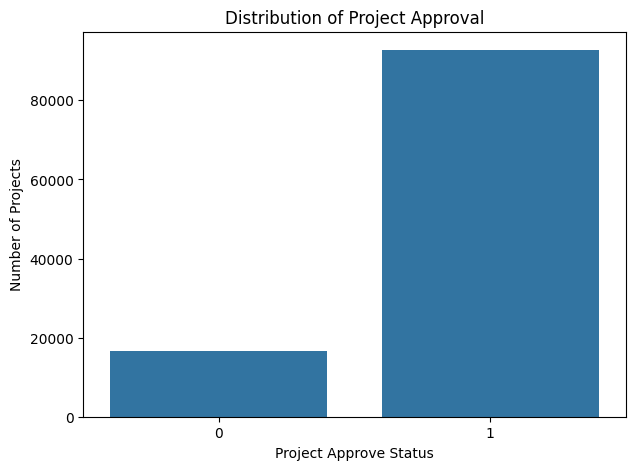

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=df['project_is_approved'].value_counts().index,
    y=df['project_is_approved'].value_counts().values,
)

plt.title('Distribution of Project Approval')
plt.xlabel('Project Approve Status')
plt.ylabel('Number of Projects')

plt.show()

#2. NLP Preprocessing Pipeline

In [ ]:
# Separate input features
X = df[
    ['cleaned_titles',
     'cleaned_essays',
     'cleaned_summary']
].copy()

# Separate target variable
y = df['project_is_approved']

# Check shapes
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (109248, 3)
y shape: (109248,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (87398, 3)
Testing data: (21850, 3)

Training target distribution:
project_is_approved
1    74164
0    13234
Name: count, dtype: int64

Testing target distribution:
project_is_approved
1    18542
0     3308
Name: count, dtype: int64


In [ ]:
# Check missing values in training data
print("Training missing values:")
print(X_train.isnull().sum())

# Check missing values in testing data
print("\nTesting missing values:")
print(X_test.isnull().sum())

# Handle missing values
X_train = X_train.fillna('')
X_test = X_test.fillna('')

# Verify
print("\nAfter handling missing values:")
print("Training:", X_train.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())

Training missing values:
cleaned_titles     35
cleaned_essays      0
cleaned_summary     0
dtype: int64

Testing missing values:
cleaned_titles     8
cleaned_essays     0
cleaned_summary    0
dtype: int64

After handling missing values:
Training: 0
Testing: 0


In [ ]:
#Cleaning text

import re

def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
#Clean train and test data
text_columns = [
    'cleaned_titles',
    'cleaned_essays',
    'cleaned_summary'
]

for col in text_columns:

    X_train[col] = X_train[col].apply(clean_text)

    X_test[col] = X_test[col].apply(clean_text)

print("Text cleaning completed!")

Text cleaning completed!


In [ ]:
#Tokenization
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
def tokenize_text(text):

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return tokens

In [ ]:
stop_words = set(stopwords.words('english'))

In [ ]:
for col in text_columns:

    X_train[col] = X_train[col].apply(tokenize_text)

    X_test[col] = X_test[col].apply(tokenize_text)

print("Tokenization and stopword removal completed!")

Tokenization and stopword removal completed!


In [ ]:
#Lemmatization

nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [ ]:
def lemmatize_tokens(tokens):

    lemmatized_words = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return lemmatized_words

In [ ]:
for col in text_columns:

    X_train[col] = X_train[col].apply(lemmatize_tokens)

    X_test[col] = X_test[col].apply(lemmatize_tokens)

print("Lemmatization completed!")

Lemmatization completed!


In [ ]:
from collections import Counter

for col in text_columns:

    all_words = [
        word
        for tokens in X_train[col]
        for word in tokens
    ]

    word_freq = Counter(all_words)

    print("\nColumn:", col)
    print("Total unique words:", len(word_freq))
    print("Low-frequency words:", sum(1 for w in word_freq if word_freq[w] < 2))


Column: cleaned_titles
Total unique words: 13015
Low-frequency words: 5878

Column: cleaned_essays
Total unique words: 43511
Low-frequency words: 16038

Column: cleaned_summary
Total unique words: 16781
Low-frequency words: 6525


In [ ]:
min_freq = 2

for col in text_columns:

    # Learn vocabulary from training data only
    all_words = [
        word
        for tokens in X_train[col]
        for word in tokens
    ]

    word_freq = Counter(all_words)

    # Keep words appearing at least twice
    vocab = {
        word for word, count in word_freq.items()
        if count >= min_freq
    }

    # Apply same vocabulary to train and test
    X_train[col] = X_train[col].apply(
        lambda tokens: [word for word in tokens if word in vocab]
    )

    X_test[col] = X_test[col].apply(
        lambda tokens: [word for word in tokens if word in vocab]
    )

print("Low-frequency word removal completed!")

Low-frequency word removal completed!


In [ ]:
#Prepare text for embeddings
for col in text_columns:

    X_train[col + '_text'] = X_train[col].apply(
        lambda tokens: ' '.join(tokens)
    )

    X_test[col + '_text'] = X_test[col].apply(
        lambda tokens: ' '.join(tokens)
    )

print("Final text preparation completed!")

Final text preparation completed!


#3. Embedding Approaches


In [ ]:
#TF-IDF Vectorization

# Combine the three text columns

X_train_combined = (
    X_train['cleaned_titles_text'] + ' ' +
    X_train['cleaned_essays_text'] + ' ' +
    X_train['cleaned_summary_text']
)

X_test_combined = (
    X_test['cleaned_titles_text'] + ' ' +
    X_test['cleaned_essays_text'] + ' ' +
    X_test['cleaned_summary_text']
)

print("Training documents:", len(X_train_combined))
print("Testing documents:", len(X_test_combined))

print("\nSample combined document:")
print(X_train_combined.iloc[0][:500])

Training documents: 87398
Testing documents: 21850

Sample combined document:
active learning teach title school north carolina student receive free breakfast lunch past year even student receive food local backpack program allow family food weekend included classroom student come diverse background speak english home even read grade level try hard best tool classroom provided donation go getting material literacy center classroom want provide student variety tool use meet learning need every student different therefore need differentiate help successful student money go 


In [ ]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=5000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)
X_train_tfidf = tfidf.fit_transform(X_train_combined)

X_test_tfidf = tfidf.transform(X_test_combined)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (87398, 5000)
Testing TF-IDF shape: (21850, 5000)


In [ ]:
#Word2Vec
!pip install gensim -q

In [ ]:
import gensim.downloader as api

word2vec_model = api.load('glove-wiki-gigaword-100')

print("Model loaded successfully!")
print("Embedding dimensions:", word2vec_model.vector_size)

Model loaded successfully!
Embedding dimensions: 100


In [ ]:
word = 'student'

if word in word2vec_model:
    print("Word:", word)
    print("Vector shape:", word2vec_model[word].shape)
else:
    print("Word not found!")

Word: student
Vector shape: (100,)


In [ ]:
#Averaging
def average_word2vec(tokens, model):

    vectors = [
        model[word]
        for word in tokens
        if word in model
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

In [ ]:
X_train_w2v = np.array([
    average_word2vec(tokens, word2vec_model)
    for tokens in X_train['cleaned_essays']
])

print("Training Word2Vec shape:", X_train_w2v.shape)

Training Word2Vec shape: (87398, 100)


In [ ]:
X_test_w2v = np.array([
    average_word2vec(tokens, word2vec_model)
    for tokens in X_test['cleaned_essays']
])

print("Testing Word2Vec shape:", X_test_w2v.shape)

Testing Word2Vec shape: (21850, 100)


In [ ]:
#Training Word2Vec

from gensim.models import Word2Vec

In [ ]:
train_sentences = X_train['cleaned_essays'].tolist()

In [ ]:
cbow_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    epochs=20,
    seed=42
)

print("CBOW Word2Vec trained successfully!")
print("Vocabulary size:", len(cbow_model.wv))

CBOW Word2Vec trained successfully!
Vocabulary size: 27473


In [ ]:
X_train_cbow = np.array([
    average_word2vec(tokens, cbow_model.wv)
    for tokens in X_train['cleaned_essays']
])

X_test_cbow = np.array([
    average_word2vec(tokens, cbow_model.wv)
    for tokens in X_test['cleaned_essays']
])

print("Training CBOW shape:", X_train_cbow.shape)
print("Testing CBOW shape:", X_test_cbow.shape)

Training CBOW shape: (87398, 100)
Testing CBOW shape: (21850, 100)


#4. Classical ML Models

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_train_tfidf_balanced, y_train_balanced = smote.fit_resample(
    X_train_tfidf,
    y_train
)

print("SMOTE completed!")

print("\nBefore SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

print("\nBalanced shape:", X_train_tfidf_balanced.shape)

SMOTE completed!

Before SMOTE:
project_is_approved
1    74164
0    13234
Name: count, dtype: int64

After SMOTE:
project_is_approved
0    74164
1    74164
Name: count, dtype: int64

Balanced shape: (148328, 5000)


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_tfidf_balanced,
    y_train_balanced
)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Predictions completed!")

Predictions completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Logistic Regression Performance after SMOTE")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("Precision:", precision_score(y_test, y_pred_lr))

print("Recall:", recall_score(y_test, y_pred_lr))

print("F1 Score:", f1_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Performance after SMOTE
Accuracy: 0.6909382151029748
Precision: 0.9018337991683141
Recall: 0.7134613310322511
F1 Score: 0.7966637559844629

Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.56      0.36      3308
           1       0.90      0.71      0.80     18542

    accuracy                           0.69     21850
   macro avg       0.58      0.64      0.58     21850
weighted avg       0.80      0.69      0.73     21850



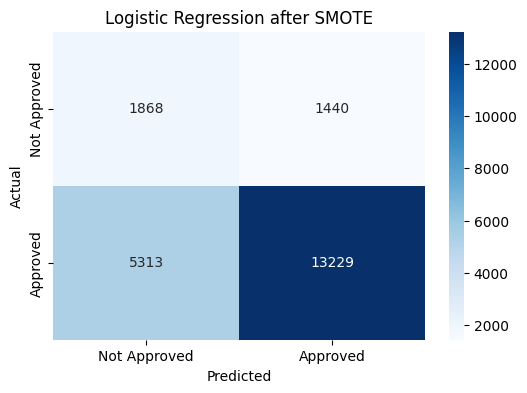

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Approved', 'Approved'],
    yticklabels=['Not Approved', 'Approved']
)

plt.title('Logistic Regression after SMOTE')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

##SVM

In [ ]:
from sklearn.svm import LinearSVC

In [ ]:
svm_model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=3000
)

svm_model.fit(
    X_train_tfidf_balanced,
    y_train_balanced
)

print("SVM training completed!")

SVM training completed!


In [ ]:
y_pred_svm = svm_model.predict(X_test_tfidf)

print("SVM predictions completed!")


SVM predictions completed!


In [ ]:
print("SVM Performance after SMOTE")

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Performance after SMOTE
Accuracy: 0.682562929061785
Precision: 0.897574677993971
Recall: 0.7065580843490454
F1 Score: 0.790693463697266

Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.55      0.34      3308
           1       0.90      0.71      0.79     18542

    accuracy                           0.68     21850
   macro avg       0.57      0.63      0.57     21850
weighted avg       0.80      0.68      0.72     21850



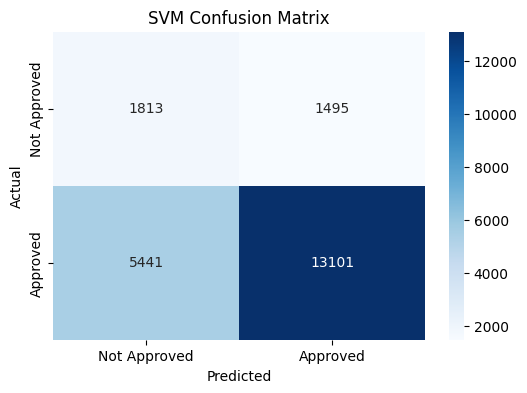

In [ ]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Approved', 'Approved'],
    yticklabels=['Not Approved', 'Approved']
)

plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

#5. Deep Learning Models

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization,
    Concatenate
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix

)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
# Convert TF-IDF to dense arrays
X_train_tfidf_dl = X_train_tfidf.toarray().astype('float32')
X_test_tfidf_dl = X_test_tfidf.toarray().astype('float32')

# Convert Word2Vec embeddings
X_train_w2v_dl = X_train_w2v.astype('float32')
X_test_w2v_dl = X_test_w2v.astype('float32')

# Convert CBOW embeddings

X_train_cbow_dl = X_train_cbow.astype('float32')
X_test_cbow_dl = X_test_cbow.astype('float32')

print("TF-IDF:", X_train_tfidf_dl.shape)
print("Word2Vec:", X_train_w2v_dl.shape)
print("CBOW:", X_train_cbow_dl.shape)

TF-IDF: (87398, 5000)
Word2Vec: (87398, 100)
CBOW: (87398, 100)
